Mounted at /content/drive
Extracted dataset to /content/dataset
Device: cuda
Detected classes (2): ['benign', 'malignant']
Total images: 3297 -> train: 2307, val: 990
Class weights: [0.9309927 1.0800562]


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


model.safetensors:   0%|          | 0.00/346M [00:00<?, ?B/s]

Model created. Backbone: vit
Trainable parameters (phase1): 149008
Phase 1: training head/CBAM only for 8 epochs


/tmp/ipython-input-875056960.py:397: FutureWarning: `torch.cuda.amp.GradScaler(args...)` is deprecated. Please use `torch.amp.GradScaler('cuda', args...)` instead.
  scaler = torch.cuda.amp.GradScaler() if (USE_AMP and torch.cuda.is_available()) else None
Train 1/51:   0%|                                                                              | 0/1154 [00:00<?, ?it/s]/tmp/ipython-input-875056960.py:407: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Val 1:   0%|                                                                                    | 0/495 [00:00<?, ?it/s]/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `to

Epoch 1/8: train_loss=0.4125 train_acc=0.8270 val_loss=0.5446 val_acc=0.8232 val_auc=0.9047 time=46.5s
Saved best model to: /content/drive/MyDrive/SkinCancer_CBAM_best.pt


... (98 outputs left out)

Train 51/51:   0%|                                                                             | 0/1154 [00:00<?, ?it/s]/tmp/ipython-input-875056960.py:407: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Val 51:   0%|                                                                                   | 0/495 [00:00<?, ?it/s]/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Val 51:   0%|       | 1/495 [00:00<00:51,  9.54it/s, b_loss=1.4092, b_acc=0.500, e_loss=1.4092, e_acc=0.500, GPU=1.14GB]/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipython-input-875056960.py:444: FutureWarning: `torch

Epoch 51/51: train_loss=0.0110 train_acc=0.9983 val_loss=1.0308 val_acc=0.8899 val_auc=0.9414 time=96.5s
Loading best model: /content/drive/MyDrive/SkinCancer_CBAM_best.pt


Val final:   0%|                                                                                | 0/495 [00:00<?, ?it/s]/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
Val final:   0%|    | 1/495 [00:00<01:07,  7.31it/s, b_loss=0.0284, b_acc=1.000, e_loss=0.0284, e_acc=1.000, GPU=1.30GB]/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.amp.autocast():
/tmp/ipython-input-875056960.py:444: FutureWarning: `torch.cuda.amp.autocast(args...)` is deprecated. Please use `torch.amp.autocast('cuda', args...)` instead.
  with torch.cuda.


FINAL VALIDATION ACCURACY: 0.8909

Classification Report:
               precision    recall  f1-score   support

      benign       0.90      0.91      0.90       561
   malignant       0.88      0.87      0.87       429

    accuracy                           0.89       990
   macro avg       0.89      0.89      0.89       990
weighted avg       0.89      0.89      0.89       990

F1 macro: 0.8889  F1 weighted: 0.8909
Macro AUC: 0.9579079565710582


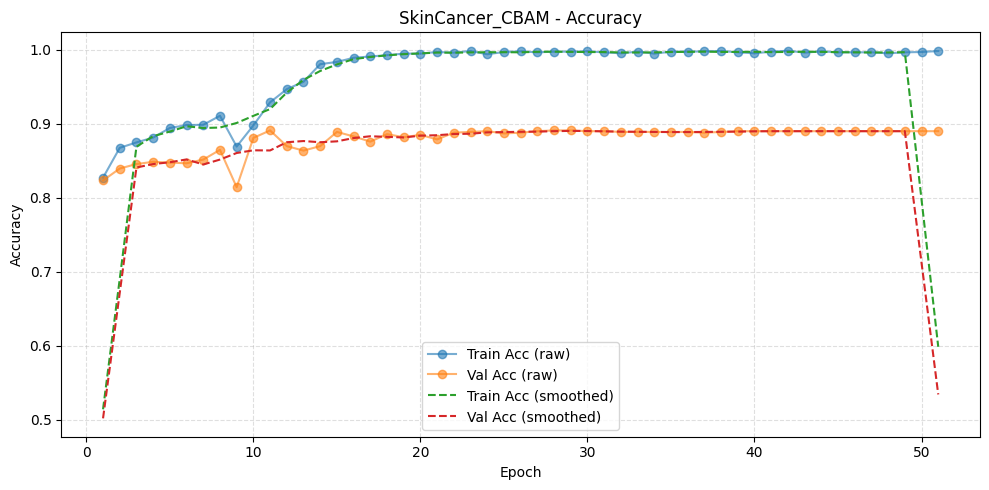

Saved accuracy plot to: /content/drive/MyDrive/diabetic_eye_results/SkinCancer_CBAM/SkinCancer_CBAM_accuracy.png


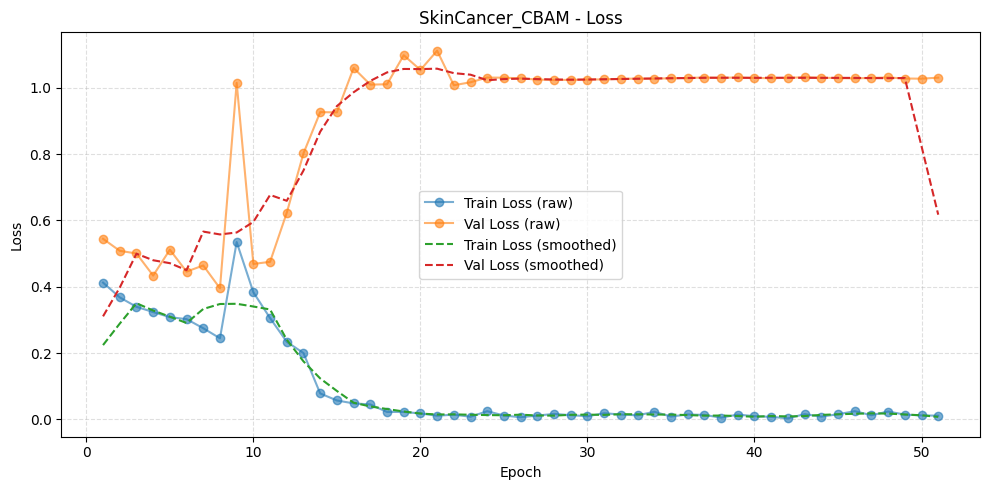

Saved loss plot to: /content/drive/MyDrive/diabetic_eye_results/SkinCancer_CBAM/SkinCancer_CBAM_loss.png


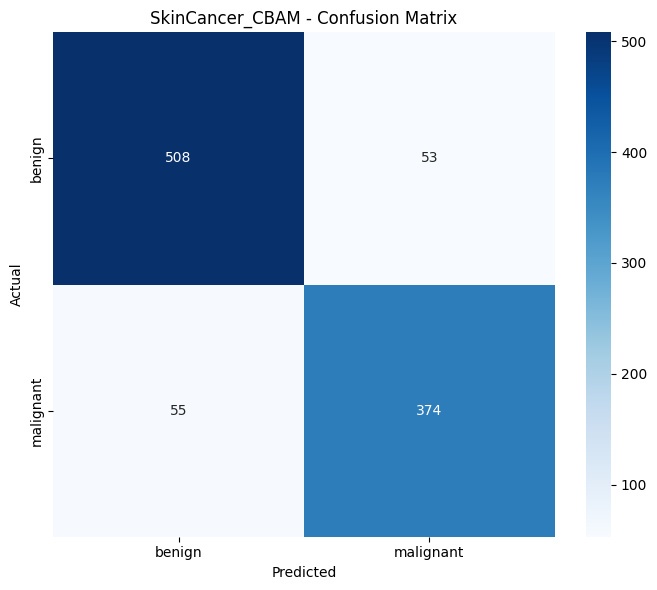

Saved confusion matrix to: /content/drive/MyDrive/diabetic_eye_results/SkinCancer_CBAM/SkinCancer_CBAM_confusion_matrix.png


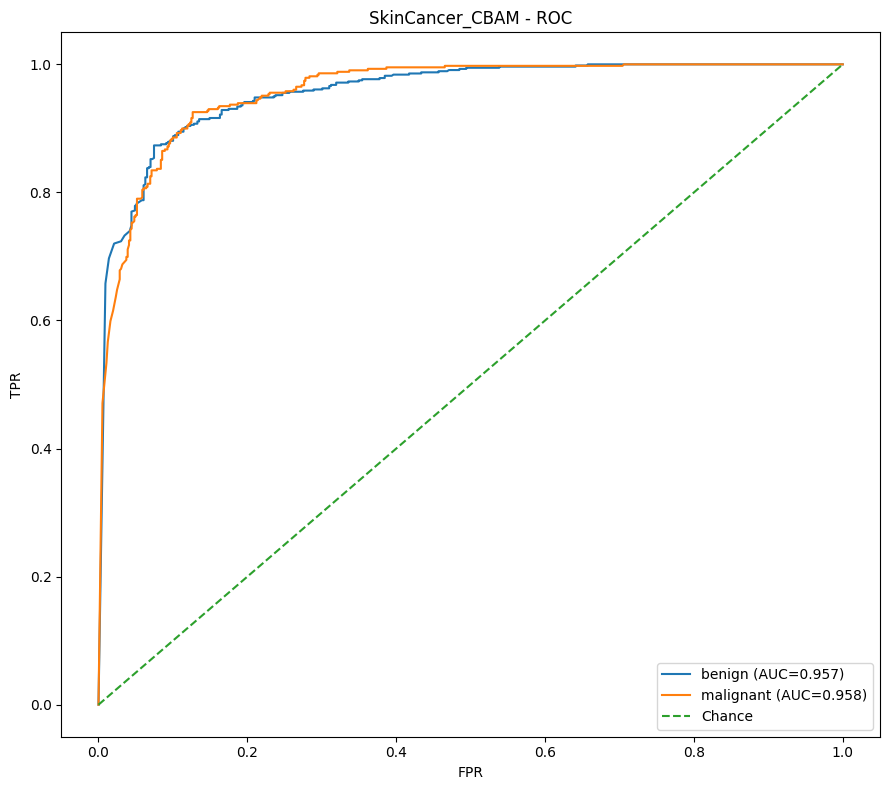

Saved ROC plot to: /content/drive/MyDrive/diabetic_eye_results/SkinCancer_CBAM/SkinCancer_CBAM_roc.png
Saved final model to: /content/drive/MyDrive/SkinCancer_CBAM_final.pt


In [1]:
# Full updated training script: ViT/ResNet + CBAM + 70/30 split + metrics & smoothing
# Requirements: torch, torchvision, timm, scikit-learn, tqdm, matplotlib, seaborn, pillow
# !pip install -q torch torchvision timm scikit-learn tqdm matplotlib seaborn pillow

import os, random, time, zipfile
from glob import glob
from collections import defaultdict

import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import AdamW
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torchvision import transforms, datasets, models
import timm
from tqdm import tqdm

from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             roc_curve, auc, precision_recall_fscore_support)
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_class_weight

# ---------------- CONFIG ----------------
DRIVE_MOUNT = True
ZIP_PATH = "/content/drive/MyDrive/d.zip"            # dataset zip on Drive (optional)
EXTRACT_PATH = "/content/dataset"
TRAIN_DIR = "/content/dataset/d/train"   # existing train folder (optional)
VAL_DIR   = "/content/dataset/d/val"     # existing val folder (optional)
# If you keep separate train/val folders, script will combine them and resplit 70/30 deterministically.

BASE_GRAPH_DIR = "/content/drive/MyDrive/diabetic_eye_results"
MODEL_NAME = "SkinCancer_CBAM"   # experiment name (change as desired)
TIMM_MODEL = "vit_base_patch16_224"  # timm model name for ViT
BACKBONE = "vit"  # "vit" or "resnet"  <-- choose here

GRAPH_DIR = os.path.join(BASE_GRAPH_DIR, MODEL_NAME)
CHECKPOINT_PATH = f"/content/drive/MyDrive/{MODEL_NAME}_best.pt"
FINAL_MODEL_PATH = f"/content/drive/MyDrive/{MODEL_NAME}_final.pt"

IMG_SIZE = 224
BATCH_SIZE = 2
NUM_WORKERS = 2
SEED = 42
PHASE1_EPOCHS = 8
PHASE2_EPOCHS = 43
N_UNFREEZE = 6      # for ViT: last transformer blocks; for ResNet we will unfreeze layer4
TRAIN_FRACTION = 0.7
SMOOTH_WINDOW = 5
USE_AMP = True      # automatic mixed precision (if available)
SHOW_GPU_MEM = True

# ---------------- reproducibility ----------------
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

# ---------------- Colab drive mount & zip extract (optional) ----------------
if DRIVE_MOUNT:
    try:
        from google.colab import drive
        drive.mount('/content/drive', force_remount=False)
    except Exception:
        pass

if os.path.exists(ZIP_PATH) and not os.path.exists(EXTRACT_PATH):
    with zipfile.ZipFile(ZIP_PATH, 'r') as z:
        z.extractall(EXTRACT_PATH)
        print("Extracted dataset to", EXTRACT_PATH)
else:
    print("Zip not found or already extracted (or path unchanged).")

os.makedirs(GRAPH_DIR, exist_ok=True)
os.makedirs(os.path.dirname(CHECKPOINT_PATH), exist_ok=True)

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ---------------- collect images & deterministic 70/30 split ----------------
def collect_image_paths(dirs):
    samples = []
    for root in dirs:
        if not root or not os.path.exists(root):
            continue
        for cls in sorted(os.listdir(root)):
            cls_dir = os.path.join(root, cls)
            if not os.path.isdir(cls_dir):
                continue
            for p in glob(os.path.join(cls_dir, "*")):
                if os.path.isfile(p):
                    samples.append((p, cls))
    return samples

combined = collect_image_paths([TRAIN_DIR, VAL_DIR])
if len(combined) == 0:
    raise FileNotFoundError(f"No images found. Check TRAIN_DIR/VAL_DIR paths: {TRAIN_DIR}, {VAL_DIR}")

classes = sorted(list({c for _, c in combined}))
num_classes = len(classes)
class_to_idx = {c:i for i,c in enumerate(classes)}
print(f"Detected classes ({num_classes}): {classes}")

samples = [(p, class_to_idx[c]) for p,c in combined]
random.Random(SEED).shuffle(samples)
n_total = len(samples)
n_train = int(TRAIN_FRACTION * n_total)
train_samples = samples[:n_train]
val_samples = samples[n_train:]
print(f"Total images: {n_total} -> train: {len(train_samples)}, val: {len(val_samples)}")

# ---------------- transforms ----------------
IMAGENET_MEAN = (0.485, 0.456, 0.406)
IMAGENET_STD  = (0.229, 0.224, 0.225)

train_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.RandomResizedCrop(IMG_SIZE, scale=(0.8,1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(20),
    transforms.ColorJitter(0.12,0.12,0.12,0.02),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])
val_transform = transforms.Compose([
    transforms.Resize(256),
    transforms.CenterCrop(IMG_SIZE),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD)
])

# ---------------- Dataset class ----------------
from torch.utils.data import Dataset, DataLoader
class ImagePathDataset(Dataset):
    def __init__(self, samples, transform=None):
        self.samples = samples
        self.transform = transform
    def __len__(self):
        return len(self.samples)
    def __getitem__(self, idx):
        path, label = self.samples[idx]
        img = Image.open(path).convert("RGB")
        if self.transform:
            img = self.transform(img)
        return img, label

train_dataset = ImagePathDataset(train_samples, transform=train_transform)
val_dataset   = ImagePathDataset(val_samples, transform=val_transform)
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=NUM_WORKERS, pin_memory=True)
val_loader   = DataLoader(val_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=NUM_WORKERS, pin_memory=True)

# ---------------- class weights ----------------
y_train = [lbl for _,lbl in train_samples]
if num_classes > 1 and len(y_train) > 0:
    class_weights_np = compute_class_weight(class_weight='balanced', classes=np.arange(num_classes), y=y_train)
    class_weights = torch.tensor(class_weights_np, dtype=torch.float).to(device)
    print("Class weights:", class_weights.cpu().numpy())
else:
    class_weights = None

# ---------------- CBAM (conv-style) for CNN feature maps ----------------
class ChannelAttention(nn.Module):
    def __init__(self, in_planes, ratio=16):
        super().__init__()
        self.fc = nn.Sequential(
            nn.Conv2d(in_planes, in_planes // ratio, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_planes // ratio, in_planes, 1, bias=False)
        )
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg = self.fc(F.adaptive_avg_pool2d(x,1))
        mx  = self.fc(F.adaptive_max_pool2d(x,1))
        return self.sigmoid(avg + mx)

class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        assert kernel_size in (3,7)
        padding = 3 if kernel_size==7 else 1
        self.conv = nn.Conv2d(2,1,kernel_size,padding=padding,bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):
        avg = torch.mean(x, dim=1, keepdim=True)
        mx,_ = torch.max(x, dim=1, keepdim=True)
        cat = torch.cat([avg,mx], dim=1)
        return self.sigmoid(self.conv(cat))

class CBAMBlock(nn.Module):
    def __init__(self, channels, ratio=16, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttention(channels, ratio)
        self.sa = SpatialAttention(kernel_size)
    def forward(self, x):
        x = x * self.ca(x)
        x = x * self.sa(x)
        return x

# ---------------- CBAM for ViT tokens (token-level Channel + Token/spatial) ----------------
class ChannelAttentionToken(nn.Module):
    def __init__(self, channels, reduction=8):
        super().__init__()
        self.fc1 = nn.Linear(channels, channels // reduction, bias=False)
        self.relu = nn.ReLU(inplace=True)
        self.fc2 = nn.Linear(channels // reduction, channels, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):  # x: B x N x C
        x_pool = x.mean(dim=1)   # B x C
        y = self.fc1(x_pool)
        y = self.relu(y)
        y = self.fc2(y)
        y = self.sigmoid(y).unsqueeze(1)  # B x 1 x C
        return x * y

class SpatialAttentionToken(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        padding = (kernel_size - 1) // 2
        self.conv = nn.Conv1d(in_channels=2, out_channels=1, kernel_size=kernel_size, padding=padding, bias=False)
        self.sigmoid = nn.Sigmoid()
    def forward(self, x):  # x: B x N x C
        avg_out = x.mean(dim=2, keepdim=True)      # B x N x 1
        max_out, _ = x.max(dim=2, keepdim=True)    # B x N x 1
        cat = torch.cat([avg_out, max_out], dim=2) # B x N x 2
        cat = cat.permute(0,2,1)                   # B x 2 x N
        attn = self.conv(cat)                      # B x 1 x N
        attn = self.sigmoid(attn).permute(0,2,1)   # B x N x 1
        return x * attn

class CBAMTokens(nn.Module):
    def __init__(self, channels, reduction=8, kernel_size=7):
        super().__init__()
        self.ca = ChannelAttentionToken(channels, reduction=reduction)
        self.sa = SpatialAttentionToken(kernel_size=kernel_size)
    def forward(self, x):
        x = self.ca(x)
        x = self.sa(x)
        return x

# ---------------- Build backbone + attach CBAM ----------------
def build_model(backbone="vit", num_classes=2):
    if backbone == "vit":
        timm_name = TIMM_MODEL
        base = timm.create_model(timm_name, pretrained=True, num_classes=num_classes)
        embed_dim = getattr(base, "embed_dim", None) or getattr(base, "num_features", None) or 768
        cbam_tokens = CBAMTokens(channels=embed_dim, reduction=8, kernel_size=7)

        class ViTWithTokenCBAM(nn.Module):
            def __init__(self, timm_model, cbam):
                super().__init__()
                self.model = timm_model
                self.cbam = cbam
                try:
                    self.classifier = self.model.get_classifier()
                except Exception:
                    if hasattr(self.model, "head"):
                        self.classifier = self.model.head
                    else:
                        self.classifier = nn.Linear(embed_dim, num_classes)
            def forward(self, x):
                # typical timm ViT flow
                if hasattr(self.model, "patch_embed") and hasattr(self.model, "pos_embed"):
                    x = self.model.patch_embed(x)  # B x N x C
                    if hasattr(self.model, "cls_token"):
                        cls_token = self.model.cls_token.expand(x.shape[0], -1, -1)
                        x = torch.cat((cls_token, x), dim=1)
                    if hasattr(self.model, "pos_embed"):
                        # broadcast pos_embed if shapes match
                        x = x + self.model.pos_embed
                    if hasattr(self.model, "pos_drop"):
                        x = self.model.pos_drop(x)
                    if hasattr(self.model, "blocks"):
                        for blk in self.model.blocks:
                            x = blk(x)
                    elif hasattr(self.model, "vit") and hasattr(self.model.vit, "blocks"):
                        for blk in self.model.vit.blocks:
                            x = blk(x)
                    if hasattr(self.model, "norm"):
                        x = self.model.norm(x)
                    x = self.cbam(x)        # B x (N+1) x C
                    pooled = x[:,0]         # cls token
                    try:
                        out = self.classifier(pooled)
                    except Exception:
                        out = self.classifier(pooled)
                    return out
                # fallback
                return self.model(x)
        return ViTWithTokenCBAM(base, cbam_tokens)

    elif backbone == "resnet":
        base = models.resnet50(weights=models.ResNet50_Weights.IMAGENET1K_V2)
        in_feats = base.fc.in_features
        # remove final fc
        base.fc = nn.Identity()
        cb = CBAMBlock(in_feats, ratio=16, kernel_size=7)
        class ResNetCBAM(nn.Module):
            def __init__(self, base, cbam, num_classes):
                super().__init__()
                self.base = base
                self.cbam = cbam
                self.pool = nn.AdaptiveAvgPool2d((1,1))
                self.classifier = nn.Sequential(
                    nn.Dropout(0.4),
                    nn.Linear(in_feats, 512),
                    nn.ReLU(inplace=True),
                    nn.Dropout(0.3),
                    nn.Linear(512, num_classes)
                )
            def forward(self, x):
                feat_map = self.base(x)   # B x C x H x W
                feat_map = self.cbam(feat_map)
                pooled = self.pool(feat_map).flatten(1)
                return self.classifier(pooled)
        return ResNetCBAM(base, cb, num_classes)
    else:
        raise ValueError("backbone must be 'vit' or 'resnet'")

model = build_model(BACKBONE, num_classes=num_classes).to(device)
print("Model created. Backbone:", BACKBONE)

# ---------------- Phase 1: freeze encoder, train head/CBAM ----------------
for name, p in model.named_parameters():
    p.requires_grad = False

# unfreeze classifier & cbam parameters
for name, p in model.named_parameters():
    if "classifier" in name or "classif" in name or "head" in name or "cbam" in name or "cbam" in name:
        p.requires_grad = True
# ensure cbam params trainable if exist
if hasattr(model, "cbam"):
    for p in model.cbam.parameters():
        p.requires_grad = True

# For ViT wrapper, also ensure wrapper's classifier trainable
if BACKBONE == "vit":
    for name, p in model.named_parameters():
        if "classifier" in name or "head" in name:
            p.requires_grad = True

# count trainable params
n_trainable = sum(p.numel() for p in model.parameters() if p.requires_grad)
print("Trainable parameters (phase1):", n_trainable)

# ---------------- Loss, optimizer, scheduler ----------------
criterion = nn.CrossEntropyLoss(weight=class_weights) if class_weights is not None else nn.CrossEntropyLoss()
optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=2e-4, weight_decay=1e-2)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.3, patience=2)

# ---------------- utils ----------------
def human_gpu_mem():
    if not torch.cuda.is_available() or not SHOW_GPU_MEM:
        return ""
    return f"{torch.cuda.memory_reserved(device)/1024**3:.2f}GB"

def smooth(x, window=SMOOTH_WINDOW):
    if len(x) < window:
        return x
    return np.convolve(x, np.ones(window)/window, mode='same')

def compute_metrics_full(y_true, y_pred, y_prob, class_names):
    y_true = np.array(y_true)
    y_pred = np.array(y_pred)
    acc = accuracy_score(y_true, y_pred) if len(y_true)>0 else 0.0
    prec_macro, rec_macro, f1_macro, _ = precision_recall_fscore_support(y_true, y_pred, average='macro', zero_division=0)
    prec_wt, rec_wt, f1_wt, _ = precision_recall_fscore_support(y_true, y_pred, average='weighted', zero_division=0)
    report = classification_report(y_true, y_pred, target_names=class_names, zero_division=0)
    n = len(class_names)
    y_prob = np.array(y_prob) if len(y_prob)>0 else np.zeros((0,n))
    y_true_bin = label_binarize(y_true, classes=list(range(n)))
    if y_true_bin.ndim == 1:
        y_true_bin = y_true_bin.reshape(-1,1)
    if y_true_bin.shape[1] == 1:
        y_true_bin = np.hstack([1-y_true_bin, y_true_bin])
    fpr, tpr, roc_auc = {}, {}, {}
    aucs = []; missing = []
    for i in range(n):
        if y_true_bin.shape[0]==0 or np.sum(y_true_bin[:,i])==0:
            missing.append(class_names[i]); continue
        try:
            fpr[i], tpr[i], _ = roc_curve(y_true_bin[:,i], y_prob[:,i])
            roc_auc[i] = auc(fpr[i], tpr[i])
            aucs.append(roc_auc[i])
        except Exception:
            missing.append(class_names[i])
    macro_auc = np.mean(aucs) if len(aucs)>0 else 0.0
    return {"accuracy":acc, "precision_macro":prec_macro, "recall_macro":rec_macro, "f1_macro":f1_macro,
            "precision_weighted":prec_wt, "recall_weighted":rec_wt, "f1_weighted":f1_wt,
            "report":report, "roc_auc":roc_auc, "fpr":fpr, "tpr":tpr, "macro_auc":macro_auc, "missing":missing}

# ---------------- train & validate functions ----------------
scaler = torch.cuda.amp.GradScaler() if (USE_AMP and torch.cuda.is_available()) else None

def train_one_epoch(model, loader, optimizer, device, epoch, total_epochs):
    model.train()
    running_loss=0.0; correct=0; total=0
    pbar = tqdm(enumerate(loader, start=1), total=len(loader), desc=f"Train {epoch}/{total_epochs}", leave=False, ncols=120)
    for batch_idx, (imgs, labels) in pbar:
        imgs = imgs.to(device); labels = labels.to(device)
        optimizer.zero_grad()
        if scaler:
            with torch.cuda.amp.autocast():
                logits = model(imgs)
                loss = criterion(logits, labels)
            scaler.scale(loss).backward()
            scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(model.parameters(), 3.0)
            scaler.step(optimizer)
            scaler.update()
        else:
            logits = model(imgs)
            loss = criterion(logits, labels)
            loss.backward()
            torch.nn.utils.clip_grad_norm_(model.parameters(), 3.0)
            optimizer.step()
        running_loss += loss.item() * imgs.size(0)
        preds = logits.argmax(dim=1)
        correct += (preds == labels).sum().item()
        total += imgs.size(0)
        b_acc = (preds == labels).float().mean().item()
        running_epoch_loss = running_loss / total
        running_epoch_acc = correct/total
        postfix = {"b_loss":f"{loss.item():.4f}","b_acc":f"{b_acc:.3f}","e_loss":f"{running_epoch_loss:.4f}","e_acc":f"{running_epoch_acc:.3f}"}
        if torch.cuda.is_available() and SHOW_GPU_MEM:
            postfix["GPU"] = human_gpu_mem()
        pbar.set_postfix(postfix, refresh=False)
    pbar.close()
    return running_loss/len(loader.dataset), correct/total if total>0 else 0.0

def validate(model, loader, device, epoch=None):
    model.eval()
    running_loss=0.0
    all_preds=[]; all_labels=[]; all_probs=[]
    pbar = tqdm(enumerate(loader, start=1), total=len(loader), desc=f"Val {epoch}" if epoch else "Val", leave=False, ncols=120)
    with torch.no_grad():
        for batch_idx, (imgs, labels) in pbar:
            imgs = imgs.to(device); labels = labels.to(device)
            if scaler:
                with torch.cuda.amp.autocast():
                    logits = model(imgs)
                    loss = criterion(logits, labels)
            else:
                logits = model(imgs)
                loss = criterion(logits, labels)
            running_loss += loss.item() * imgs.size(0)
            probs = F.softmax(logits, dim=1).cpu().numpy()
            preds = np.argmax(probs, axis=1)
            all_probs.append(probs); all_preds.extend(list(preds)); all_labels.extend(list(labels.cpu().numpy()))
            batch_acc = (preds == labels.cpu().numpy()).mean()
            running_epoch_loss = running_loss / (len(all_labels) if len(all_labels)>0 else 1)
            running_epoch_acc = accuracy_score(all_labels, all_preds) if len(all_labels)>0 else 0
            postfix = {"b_loss":f"{loss.item():.4f}","b_acc":f"{batch_acc:.3f}","e_loss":f"{running_epoch_loss:.4f}","e_acc":f"{running_epoch_acc:.3f}"}
            if torch.cuda.is_available() and SHOW_GPU_MEM:
                postfix["GPU"] = human_gpu_mem()
            pbar.set_postfix(postfix, refresh=False)
    pbar.close()
    val_loss = running_loss / len(loader.dataset) if len(loader.dataset)>0 else 0.0
    all_probs = np.vstack(all_probs) if all_probs else np.zeros((0, num_classes))
    return val_loss, all_labels, all_preds, all_probs

# ---------------- training loop (phase1) ----------------
history = {"train_loss":[], "train_acc":[], "val_loss":[], "val_acc":[], "val_auc_macro":[]}
best_val_loss = float('inf'); best_auc_macro = 0.0
total_epochs = PHASE1_EPOCHS + PHASE2_EPOCHS

print("Phase 1: training head/CBAM only for", PHASE1_EPOCHS, "epochs")
for epoch in range(1, PHASE1_EPOCHS+1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, device, epoch, total_epochs)
    val_loss, y_true_val, y_pred_val, y_prob_val = validate(model, val_loader, device, epoch)
    metrics = compute_metrics_full(y_true_val, y_pred_val, y_prob_val, classes)
    scheduler.step(val_loss)
    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(metrics["accuracy"]); history["val_auc_macro"].append(metrics["macro_auc"])
    print(f"Epoch {epoch}/{PHASE1_EPOCHS}: train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_loss={val_loss:.4f} val_acc={metrics['accuracy']:.4f} val_auc={metrics['macro_auc']:.4f} time={time.time()-t0:.1f}s")
    if val_loss < best_val_loss or metrics["macro_auc"] > best_auc_macro:
        best_val_loss = min(best_val_loss, val_loss)
        best_auc_macro = max(best_auc_macro, metrics["macro_auc"])
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print("Saved best model to:", CHECKPOINT_PATH)

# ---------------- Phase 2: unfreeze and finetune ----------------
print("Phase 2: unfreezing last blocks / final layers for fine-tuning")
try:
    if BACKBONE == "vit":
        if hasattr(model.model, "blocks"):
            total_blocks = len(model.model.blocks)
            for i in range(max(0, total_blocks - N_UNFREEZE), total_blocks):
                for p in model.model.blocks[i].parameters():
                    p.requires_grad = True
        elif hasattr(model.model, "vit") and hasattr(model.model.vit, "blocks"):
            total_blocks = len(model.model.vit.blocks)
            for i in range(max(0, total_blocks - N_UNFREEZE), total_blocks):
                for p in model.model.vit.blocks[i].parameters():
                    p.requires_grad = True
        else:
            print("Could not locate ViT blocks — unfreezing entire model.")
            for p in model.parameters():
                p.requires_grad = True
    elif BACKBONE == "resnet":
        # unfreeze layer4 and classifier
        for name, p in model.named_parameters():
            if name.startswith("base.layer4") or "classifier" in name or "cbam" in name:
                p.requires_grad = True
        # if nothing changed, unfreeze all
        if sum(1 for p in model.parameters() if p.requires_grad) == 0:
            for p in model.parameters(): p.requires_grad = True
except Exception as e:
    print("Unfreeze fallback:", e)
    for p in model.parameters(): p.requires_grad = True

optimizer = AdamW(filter(lambda p: p.requires_grad, model.parameters()), lr=1e-5, weight_decay=1e-2)
scheduler = ReduceLROnPlateau(optimizer, mode='min', factor=0.3, patience=2)

for epoch in range(PHASE1_EPOCHS+1, total_epochs+1):
    t0 = time.time()
    train_loss, train_acc = train_one_epoch(model, train_loader, optimizer, device, epoch, total_epochs)
    val_loss, y_true_val, y_pred_val, y_prob_val = validate(model, val_loader, device, epoch)
    metrics = compute_metrics_full(y_true_val, y_pred_val, y_prob_val, classes)
    scheduler.step(val_loss)
    history["train_loss"].append(train_loss); history["train_acc"].append(train_acc)
    history["val_loss"].append(val_loss); history["val_acc"].append(metrics["accuracy"]); history["val_auc_macro"].append(metrics["macro_auc"])
    print(f"Epoch {epoch}/{total_epochs}: train_loss={train_loss:.4f} train_acc={train_acc:.4f} val_loss={val_loss:.4f} val_acc={metrics['accuracy']:.4f} val_auc={metrics['macro_auc']:.4f} time={time.time()-t0:.1f}s")
    if val_loss < best_val_loss or metrics["macro_auc"] > best_auc_macro:
        best_val_loss = min(best_val_loss, val_loss)
        best_auc_macro = max(best_auc_macro, metrics["macro_auc"])
        torch.save(model.state_dict(), CHECKPOINT_PATH)
        print("Saved best model to:", CHECKPOINT_PATH)

# ---------------- Final evaluation ----------------
print("Loading best model:", CHECKPOINT_PATH)
model.load_state_dict(torch.load(CHECKPOINT_PATH, map_location=device))
model.to(device)
model.eval()

val_loss, y_true_val, y_pred_val, y_prob_val = validate(model, val_loader, device, epoch="final")
metrics = compute_metrics_full(y_true_val, y_pred_val, y_prob_val, classes)

print("\nFINAL VALIDATION ACCURACY: {:.4f}".format(metrics["accuracy"]))
print("\nClassification Report:\n", metrics["report"])
print("F1 macro: {:.4f}  F1 weighted: {:.4f}".format(metrics["f1_macro"], metrics["f1_weighted"]))
print("Macro AUC:", metrics["macro_auc"])
if metrics["missing"]:
    print("Skipped ROC for classes (no positive samples):", metrics["missing"])

# ---------------- Save & plot raw + smoothed curves ----------------
os.makedirs(GRAPH_DIR, exist_ok=True)
epochs_range = range(1, len(history["train_loss"])+1)

plt.figure(figsize=(10,5))
plt.plot(epochs_range, history["train_acc"], marker='o', alpha=0.6, label='Train Acc (raw)')
plt.plot(epochs_range, history["val_acc"], marker='o', alpha=0.6, label='Val Acc (raw)')
plt.plot(epochs_range, smooth(history["train_acc"]), linestyle='--', label='Train Acc (smoothed)')
plt.plot(epochs_range, smooth(history["val_acc"]), linestyle='--', label='Val Acc (smoothed)')
plt.xlabel("Epoch"); plt.ylabel("Accuracy"); plt.title(f"{MODEL_NAME} - Accuracy"); plt.grid(True, linestyle='--', alpha=0.4); plt.legend()
acc_path = os.path.join(GRAPH_DIR, f"{MODEL_NAME}_accuracy.png")
plt.tight_layout(); plt.savefig(acc_path, dpi=150); plt.show()
print("Saved accuracy plot to:", acc_path)

plt.figure(figsize=(10,5))
plt.plot(epochs_range, history["train_loss"], marker='o', alpha=0.6, label='Train Loss (raw)')
plt.plot(epochs_range, history["val_loss"], marker='o', alpha=0.6, label='Val Loss (raw)')
plt.plot(epochs_range, smooth(history["train_loss"]), linestyle='--', label='Train Loss (smoothed)')
plt.plot(epochs_range, smooth(history["val_loss"]), linestyle='--', label='Val Loss (smoothed)')
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title(f"{MODEL_NAME} - Loss"); plt.grid(True, linestyle='--', alpha=0.4); plt.legend()
loss_path = os.path.join(GRAPH_DIR, f"{MODEL_NAME}_loss.png")
plt.tight_layout(); plt.savefig(loss_path, dpi=150); plt.show()
print("Saved loss plot to:", loss_path)

cm = confusion_matrix(y_true_val, y_pred_val, labels=list(range(num_classes)))
plt.figure(figsize=(7,6))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=classes, yticklabels=classes)
plt.xlabel("Predicted"); plt.ylabel("Actual"); plt.title(f"{MODEL_NAME} - Confusion Matrix"); plt.tight_layout()
cm_path = os.path.join(GRAPH_DIR, f"{MODEL_NAME}_confusion_matrix.png")
plt.savefig(cm_path, dpi=150); plt.show()
print("Saved confusion matrix to:", cm_path)

plt.figure(figsize=(9,8))
plotted=False
for i in range(num_classes):
    if i in metrics["roc_auc"]:
        plt.plot(metrics["fpr"][i], metrics["tpr"][i], label=f"{classes[i]} (AUC={metrics['roc_auc'][i]:.3f})"); plotted=True
plt.plot([0,1],[0,1], linestyle='--', label='Chance')
if plotted:
    plt.title(f"{MODEL_NAME} - ROC"); plt.xlabel("FPR"); plt.ylabel("TPR"); plt.legend(loc='lower right')
    roc_path = os.path.join(GRAPH_DIR, f"{MODEL_NAME}_roc.png"); plt.tight_layout(); plt.savefig(roc_path, dpi=150); plt.show()
    print("Saved ROC plot to:", roc_path)
else:
    print("No ROC curves (some classes missing positives).")

# ---------------- Save final model ----------------
torch.save(model.state_dict(), FINAL_MODEL_PATH)
print("Saved final model to:", FINAL_MODEL_PATH)
